# 과제 4 — Diffusion Policy 학습 및 ACT 비교

**과제 내용**: 과제 3과 같은 데이터셋으로 Diffusion Policy를 학습하고, 실제 로봇에서 10회 평가해 과제 3의 ACT 정책과 성공률·동작의 부드러움·반응성을 비교한다. 같은 Diffusion Policy를 DDIM 스케줄러로 denoising 횟수만 10으로 줄여 10회 더 평가하고, denoising 횟수가 성공률과 실시간성에 주는 영향을 분석한다. 학습된 정책은 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1~3과 같은 저장소, assignments 폴더)에 `assignment_4.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고, 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- Diffusion Policy는 과제 3의 ACT와 **같은 학습 데이터셋**으로 학습해야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 비교 대상 ACT는 과제 3에서 성공률이 가장 높았던 chunk_size의 정책을 쓴다. 과제 3 이후 평가 환경(조명, 카메라 위치, 물체 위치 표시)이 바뀌지 않았다면 과제 3의 ACT 평가 결과를 **재사용해도 된다.** 바뀌었다면 ACT도 다시 10회 평가한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

In [21]:
from huggingface_hub import HfApi

api = HfApi()
public_api = HfApi(token=False)

repos = [
    "yhks/rollout_diffusion_my_task_20261122_172437",
    "yhks/rollout_diffusion_my_task_ddim10_20261122_174115",
]

required_files = [
    "meta/info.json",
    "meta/tasks.parquet",
    "meta/stats.json",
    "data/chunk-000/file-000.parquet",
    "videos/observation.images.overhead/chunk-000/file-000.mp4",
    "videos/observation.images.wrist/chunk-000/file-000.mp4",
]

for repo_id in repos:
    # 기존 저장소도 확실하게 공개로 변경
    api.update_repo_settings(
        repo_id=repo_id,
        repo_type="dataset",
        private=False,
    )

    # 로그인하지 않은 사람도 접근할 수 있는지 검사
    info = public_api.repo_info(repo_id, repo_type="dataset")
    files = public_api.list_repo_files(repo_id, repo_type="dataset")

    missing = [filename for filename in required_files if filename not in files]

    print(f"\n저장소: {repo_id}")
    print("공개 여부:", not info.private)
    print("파일 수:", len(files))
    print("필수 파일:", "통과" if not missing else f"누락 {missing}")


저장소: yhks/rollout_diffusion_my_task_20261122_172437
공개 여부: True
파일 수: 8
필수 파일: 통과

저장소: yhks/rollout_diffusion_my_task_ddim10_20261122_174115
공개 여부: True
파일 수: 8
필수 파일: 통과


## 0. 제출 정보

In [22]:
# 본인 정보
STUDENT_ID = "2021136087"
NAME = "윤희건"
HF_USER = "yhks"

# 학습 데이터에 저장된 태스크 문장과 정확히 같아야 한다.
TASK = "Grab the black cube"

# 과제 3과 동일한 학습 데이터셋
TRAIN_DATASET = "yhks/my_task"

# 현재 실제 평가 데이터셋이 존재하는 chunk100 ACT를 비교 대상으로 사용한다.
ACT_CHUNK_SIZE = 100
ACT_POLICY_REPO = "yhks/act_my_task"

# 과제 4에서 새로 학습할 Diffusion Policy 저장소
DP_POLICY_REPO = "yhks/diffusion_my_task"

# 평가 조건
CONDITIONS = ["act", "dp", "dp_ddim10"]

LABELS = {
    "act": "ACT (chunk100)",
    "dp": "DP (DDPM)",
    "dp_ddim10": "DP (DDIM 10)",
}

# ACT는 기존 평가 데이터셋을 사용한다.
# DP 두 조건은 평가 후 실제 생성된 저장소 이름으로 수정한다.
EVAL_DATASETS = {
    "act": "yhks/rollout_act_my_task_20261028_142910",
    "dp": "yhks/rollout_diffusion_my_task_20261122_172437",
    "dp_ddim10": "yhks/rollout_diffusion_my_task_ddim10_20261122_174115",
}


# Diffusion Policy 학습을 시작한 뒤 실제 W&B 주소로 수정한다.
WANDB_URL = "https://wandb.ai/yhkees-korea-university-of-technology-and-education/lerobot/runs/74imudqt"

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("ACT 정책      :", f"https://huggingface.co/{ACT_POLICY_REPO}")
print("DP 정책       :", f"https://huggingface.co/{DP_POLICY_REPO}")

for condition in CONDITIONS:
    print(
        f"{LABELS[condition]:<14} 평가 :",
        f"https://huggingface.co/datasets/{EVAL_DATASETS[condition]}",
    )

print("wandb         :", WANDB_URL or "(학습 후 입력)")

학번/이름     : 2021136087 윤희건
태스크        : Grab the black cube
학습 데이터셋 : https://huggingface.co/datasets/yhks/my_task
ACT 정책      : https://huggingface.co/yhks/act_my_task
DP 정책       : https://huggingface.co/yhks/diffusion_my_task
ACT (chunk100) 평가 : https://huggingface.co/datasets/yhks/rollout_act_my_task_20261028_142910
DP (DDPM)      평가 : https://huggingface.co/datasets/yhks/rollout_diffusion_my_task_20261122_172437
DP (DDIM 10)   평가 : https://huggingface.co/datasets/yhks/rollout_diffusion_my_task_ddim10_20261122_174115
wandb         : https://wandb.ai/yhkees-korea-university-of-technology-and-education/lerobot/runs/74imudqt


In [23]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


In [24]:
# Hub 접근 확인 — 6개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (ACT_POLICY_REPO, "model"), (DP_POLICY_REPO, "model")]
checks += [(EVAL_DATASETS[k], "dataset") for k in CONDITIONS]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] yhks/my_task  (파일 11개)
OK   [model  ] yhks/act_my_task  (파일 9개)
OK   [model  ] yhks/diffusion_my_task  (파일 9개)
OK   [dataset] yhks/rollout_act_my_task_20261028_142910  (파일 9개)
OK   [dataset] yhks/rollout_diffusion_my_task_20261122_172437  (파일 8개)
OK   [dataset] yhks/rollout_diffusion_my_task_ddim10_20261122_174115  (파일 8개)


In [18]:
from huggingface_hub import HfApi

api = HfApi()
print("로그인 계정:", api.whoami()["name"])

print("\n내 Diffusion 평가 저장소:")
for ds in api.list_datasets(author="yhks"):
    if "rollout_diffusion_my_task" in ds.id:
        print(ds.id, "| private:", ds.private)

로그인 계정: yhks

내 Diffusion 평가 저장소:
yhks/rollout_diffusion_my_task_20261122_172437_20261122_172455 | private: False
yhks/rollout_diffusion_my_task_ddim10_20261122_174115_20261122_174132 | private: False


## 1. 실험 설계

### 1-1. 배경
Diffusion Policy는 행동을 한 번에 회귀하지 않는다. 가우시안 노이즈에서 출발해 노이즈를 조금씩 걷어내며(denoising) 행동 시퀀스를 만든다. 학습할 때는 행동에 섞인 노이즈를 맞히도록 배우고, 추론할 때는 이 과정을 `num_inference_steps`번 반복한다.

- `n_obs_steps`: 정책에 넣는 과거 관측 프레임 수
- `horizon`: 한 번의 추론으로 생성하는 행동 시퀀스의 길이
- `n_action_steps`: 생성한 시퀀스 중 실제로 실행하는 스텝 수. 이만큼 실행한 뒤 다시 추론한다.

ACT와 비교하면 다음과 같다.
- ACT는 행동을 L1 손실로 직접 회귀한다. 같은 상황에서 시연이 여러 갈래로 나뉘면(예: 물체를 왼쪽에서 잡기도 하고 오른쪽에서 잡기도 함) 회귀 출력은 그 평균 쪽으로 끌려가기 쉽다. ACT는 CVAE 구조로 이 문제를 일부 완화한다.
- Diffusion Policy는 행동 분포에서 샘플링하므로 여러 갈래의 시연을 그대로 표현할 수 있다. 대신 추론할 때마다 denoising을 여러 번 반복해야 하므로 느리다.
- 학습에 쓴 DDPM 스케줄러 대신 DDIM 스케줄러를 쓰면 **재학습 없이** denoising 횟수를 줄여 추론을 빠르게 할 수 있다. 다만 횟수를 너무 줄이면 행동의 품질이 떨어질 수 있다.

아래 셀은 학습한 정책의 설정을 데이터셋의 fps로 환산해 초 단위로 보여준다.

In [8]:
# 학습 데이터셋의 fps로 관측·행동 구간 길이 환산
import pandas as pd
import matplotlib.pyplot as plt

def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
dp_cfg = load_json(DP_POLICY_REPO, "config.json") or {}
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for key in ["n_obs_steps", "horizon", "n_action_steps"]:
        v = dp_cfg.get(key)
        if v:
            print(f"{key:<15} = {v:>3d} -> {v/fps:5.2f} s")
    if dp_cfg.get("n_action_steps"):
        n_plan = ep_len_s * fps / dp_cfg["n_action_steps"]
        print(f"\n평균 에피소드 한 번에 약 {n_plan:.0f}회 다시 추론한다.")

config.json:   0%|          | 0.00/2.30k [00:00<?, ?B/s]

fps: 30, 에피소드 수: 50, 평균 에피소드 길이: 30.0 s

n_obs_steps     =   2 ->  0.07 s
horizon         =  64 ->  2.13 s
n_action_steps  =  32 ->  1.07 s

평균 에피소드 한 번에 약 28회 다시 추론한다.


### 1-2. 가설 (학습 전에 작성)
`[작성]` 결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 4절에서 분석하는 것이 더 중요하다.

- 성공률이 가장 높을 것으로 예상하는 조건(ACT / DP (DDPM) / DP (DDIM 10))과 이유: DP (DDPM)의 성공률이 가장 높을 것으로 예상한다. 검은 큐브에 접근하고 잡는 동작에는 여러 가능한 경로가 있는데, Diffusion Policy는 이런 다양한 행동을 표현할 수 있다. DDPM은 충분한 횟수로 노이즈를 제거해 행동을 생성하므로, denoising 횟수를 10으로 줄인 조건보다 안정적인 행동을 만들 것으로 예상한다.
- 동작이 가장 부드러울 것으로 예상하는 조건과 이유: DP (DDPM)의 동작이 가장 부드러울 것으로 예상한다. 여러 스텝의 행동을 하나의 시퀀스로 생성하므로 큐브에 접근하는 동안 이어지는 경로를 만들 수 있다고 생각한다. 다만 새 행동을 추론할 때 잠깐 멈춘다면 실제 영상에서는 덜 부드럽게 보일 수 있다.
- denoising 횟수를 10으로 줄였을 때 성공률과 동작이 어떻게 달라질지와 이유: DP (DDIM 10)은 행동을 만드는 계산 횟수가 줄어 추론 시간이 짧아지고, 추론할 때의 멈칫함도 줄어들 것으로 예상한다. 반면 노이즈를 제거하는 횟수가 적어 파지 위치나 접근 경로가 덜 정확해지면 DDPM보다 성공률이 낮아질 수 있다. 실제 결과가 이 예상과 다른지는 같은 시작 위치에서 각각 10회 평가해 확인한다.

### 1-3. 정책 설정 확인
아래 셀은 Diffusion Policy의 주요 설정을 출력하고, ACT와 같은 학습 데이터셋을 썼는지 확인한다.

In [9]:
act_tc = load_json(ACT_POLICY_REPO, "train_config.json") or {}
dp_tc = load_json(DP_POLICY_REPO, "train_config.json") or {}

print("[Diffusion Policy 주요 설정]")
for key in ["type", "n_obs_steps", "horizon", "n_action_steps", "noise_scheduler_type",
            "num_train_timesteps", "num_inference_steps", "crop_shape", "vision_backbone"]:
    print(f"  {key:<22}: {dp_cfg.get(key)}")
if dp_cfg and dp_cfg.get("num_inference_steps") is None:
    print("  -> num_inference_steps가 None이면 num_train_timesteps만큼 denoising한다")

cmp_df = pd.DataFrame([
    {"policy": "ACT", "dataset": act_tc.get("dataset", {}).get("repo_id"),
     "steps": act_tc.get("steps"), "batch_size": act_tc.get("batch_size"), "seed": act_tc.get("seed")},
    {"policy": "Diffusion", "dataset": dp_tc.get("dataset", {}).get("repo_id"),
     "steps": dp_tc.get("steps"), "batch_size": dp_tc.get("batch_size"), "seed": dp_tc.get("seed")},
]).set_index("policy")
display(cmp_df)

same_dataset = cmp_df["dataset"].nunique(dropna=False) == 1 and cmp_df["dataset"].notna().all()
print(("[일치]   " if same_dataset else "[불일치] ") + "학습 데이터셋")
print(("[일치]   " if dp_cfg.get("type") == "diffusion" else "[불일치] ") + f"정책 종류: {dp_cfg.get('type')}")

train_config.json:   0%|          | 0.00/6.86k [00:00<?, ?B/s]

[Diffusion Policy 주요 설정]
  type                  : diffusion
  n_obs_steps           : 2
  horizon               : 64
  n_action_steps        : 32
  noise_scheduler_type  : DDPM
  num_train_timesteps   : 100
  num_inference_steps   : None
  crop_shape            : None
  vision_backbone       : resnet18
  -> num_inference_steps가 None이면 num_train_timesteps만큼 denoising한다


,dataset,steps,batch_size,seed
policy,,,,
ACT,yhks/my_task,100000,16,1000
Diffusion,yhks/my_task,100000,2,1000


[일치]   학습 데이터셋
[일치]   정책 종류: diffusion


## 2. 학습

### 2-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 전체를 아래 코드 블록에 붙여 넣는다.

```bash
lerobot-train \
  --dataset.repo_id=yhks/my_task \
  --dataset.video_backend=pyav \
  --policy.type=diffusion \
  --policy.resize_shape='[128,128]' \
  --policy.use_amp=true \
  --policy.device=cuda \
  --policy.repo_id=yhks/diffusion_my_task \
  --policy.push_to_hub=true \
  --policy.private=false \
  --steps=100000 \
  --batch_size=2 \
  --num_workers=2 \
  --seed=1000 \
  --log_freq=200 \
  --save_freq=10000 \
  --output_dir=/home/work/lerobot/assignment_4/outputs/train/diffusion_my_task_cloud \
  --job_name=diffusion_my_task_cloud \
  --wandb.enable=true \
  2>&1 | tee /home/work/lerobot/assignment_4/logs/diffusion_my_task_cloud.log
```

> Diffusion Policy에 필요한 패키지는 `lerobot[all]`에 포함되어 있다. 학습 기본값은 `steps=100000`, `batch_size=8`이다.
>
> Diffusion Policy는 보통 ACT보다 수렴이 느려 학습 step을 더 많이 잡는다. steps와 batch_size는 과제 3과 달라도 되지만, 바꾼 이유를 2-2에 적는다. 이미지 전처리 설정(`crop_shape` 등)은 기본값이 본인 카메라 해상도에 맞는지 1-3의 출력으로 확인할 것.

### 2-2. 학습 환경
`[작성]`
- GPU: 학교 클라우드 GPU 사용. PyTorch에서 장치 이름은 `CUDA GPU`로 표시됨.
- 학습 step 수 / batch_size: 100,000 steps / 2
- 소요 시간 (과제 3의 ACT와 비교): 학습 시작 2026-11-22 00:30:38, 종료 02:04:12로 약 1시간 33분 34초. 과제 3의 ACT chunk10 학습 시간 약 6시간 51분, chunk50 학습 시간 약 7시간 21분보다 짧았다. 이번 실험은 모델 종류뿐 아니라 batch_size도 달라, 소요 시간 차이를 모델 구조만의 효과로 해석하지 않는다.
- 기본값에서 변경한 하이퍼파라미터와 이유 (없으면 "없음"): 두 카메라의 원본 영상은 각각 480×640이므로 `resize_shape=[128,128]`로 줄여 GPU 메모리 사용량을 조절했다. `batch_size=2`는 2스텝 시험 학습이 성공한 설정을 본 학습에도 적용한 것이다. `use_amp=true`로 혼합 정밀도 학습을 사용했다. 학습 데이터의 영상 디코딩에는 `video_backend=pyav`를 사용했다.

### 2-3. 학습 곡선
`[작성]` loss 곡선을 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw4.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw4.png)

In [25]:
# (선택) wandb에서 내보낸 CSV로 직접 그리기
# CSV 형식 가정: 첫 열 step, 둘째 열 loss (열 이름은 본인 파일에 맞게 수정)
import os

CSV_PATH = "images/loss_hw4.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Diffusion Policy training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

CSV 없음 — 위 마크다운의 이미지로 대체


In [11]:
# [작성] 학습 종료 시점의 손실 (학습 로그 마지막 줄에서 확인)
# Diffusion Policy는 노이즈 예측 오차(MSE)를 loss로 출력한다
dp_final_loss = 0.019
print("Diffusion Policy 마지막 기록 loss:", dp_final_loss)

Diffusion Policy 마지막 기록 loss: 0.019


## 3. 실로봇 평가 (조건별 10회)

### 3-1. 평가 프로토콜
1. 과제 3에서 표시한 물체 시작 위치 10곳을 그대로 쓴다. **세 조건 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준은 과제 3과 같게 두고 아래에 다시 적는다. 평가 도중 바꾸지 않는다.

`[작성]` 성공 기준
- 성공: 제한 시간 안에 로봇이 검은 큐브를 집어 테이블에서 완전히 들어 올리고, 2초 이상 떨어뜨리지 않고 유지한 경우
- 실패: 제한 시간 안에 큐브를 들어 올리지 못했거나, 들어 올렸더라도 2초가 지나기 전에 떨어뜨린 경우
- 에피소드 제한 시간(초): 30
- ACT 평가 결과 재사용 여부 (재사용 / 다시 평가)와 이유:
  재사용. 과제 3 평가 이후 조명, 카메라 위치, 로봇 시작 자세와 물체 시작 위치가 달라지지 않았으므로 기존 ACT chunk100의 평    가 결과를 재사용하였다. DP의 두 조건도 ACT 평가에서 사용한 10개 물체 위치와 같은 순서로 평가하였다.

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).
- Diffusion Policy는 추론이 무겁다. GPU가 있는 PC에서 돌리고, 필요하면 `--device=cuda`를 명시한다.

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어를 붙여 넣는다. DP (DDIM 10)은 같은 정책에 추론 설정만 덮어써서 평가한다. ACT를 다시 평가했다면 그 명령어도 함께 붙여 넣는다.

```bash
# DP (DDPM) — 10회 평가
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=yhks/diffusion_my_task \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.max_relative_target=5 \
  --robot.cameras="{overhead: {type: opencv, index_or_path: 4, width: 640, height: 480, fps: 25, fourcc: MJPG}, wrist: {type: opencv, index_or_path: 6, width: 640, height: 480, fps: 25, fourcc: MJPG}}" \
  --device=cuda \
  --fps=25 \
  --dataset.repo_id=yhks/rollout_diffusion_my_task_20261122_172437 \
  --dataset.root=/home/yhkfrvr/lerobot_evaluations/rollout_diffusion_my_task_20261122_172437 \
  --dataset.push_to_hub=true \
  --dataset.single_task="Grab the black cube" \
  --dataset.fps=25 \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15

# DP (DDIM 10) — 10회 평가
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=yhks/diffusion_my_task \
  --policy.noise_scheduler_type=DDIM \
  --policy.num_inference_steps=10 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.max_relative_target=5 \
  --robot.cameras="{overhead: {type: opencv, index_or_path: 4, width: 640, height: 480, fps: 25, fourcc: MJPG}, wrist: {type: opencv, index_or_path: 6, width: 640, height: 480, fps: 25, fourcc: MJPG}}" \
  --device=cuda \
  --fps=25 \
  --dataset.repo_id=yhks/rollout_diffusion_my_task_ddim10_20261122_174115 \
  --dataset.root=/home/yhkfrvr/lerobot_evaluations/rollout_diffusion_my_task_ddim10_20261122_174115 \
  --dataset.push_to_hub=true \
  --dataset.single_task="Grab the black cube" \
  --dataset.fps=25 \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15
```

In [27]:
act_info = load_json(EVAL_DATASETS["act"], "meta/info.json", repo_type="dataset")

print("ACT 평가 에피소드 수:", act_info.get("total_episodes") if act_info else "확인 실패")
print("ACT 평가 fps:", act_info.get("fps") if act_info else "확인 실패")

ACT 평가 에피소드 수: 10
ACT 평가 fps: 30


In [28]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CONDITIONS:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"{LABELS[k]:<14} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f" {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

ACT (chunk100) 에피소드 10개, 프레임 8950, fps 30  -> 통과


info.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

DP (DDPM)      에피소드 10개, 프레임 3591, fps 25  -> 통과


info.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

DP (DDIM 10)   에피소드 10개, 프레임 6973, fps 25  -> 통과
 act 이름 규칙: 통과
 dp 이름 규칙: 통과
 dp_ddim10 이름 규칙: 통과


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다. ACT 평가를 재사용했다면 과제 3의 결과를 그대로 옮긴다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. 추론 때문에 동작이 멈칫하는 구간이 보이면 함께 적는다. (예: "큐브 위치를 놓침", "다시 추론할 때마다 팔이 잠깐 멈춤", "파지 직전 좌우로 머뭇거림")

In [30]:
"""
def blank():
    return [{"episode": i, "position": i + 1, "success": None, "smooth": None, "note": ""} for i in range(10)]
"""
import pandas as pd

LABELS = {
    "act": "ACT (chunk100)",
    "dp": "DP (DDPM)",
    "dp_ddim10": "DP (DDIM 10)",
}

# ACT는 과제 3의 기존 판정을 재사용
# 0번만 성공, 나머지 9회 실패
act_smooth = [3, 2, 2, 2, 2, 2, 1, 2, 2, 2]

results = {
    "act": [
        {
            "episode": i,
            "position": i + 1,
            "success": i == 0,
            "smooth": act_smooth[i],
            "note": (
                "검은 큐브를 들어 올려 2초 이상 유지하여 성공."
                if i == 0
                else "성공 기준을 충족하지 못함. 기존 평가 기록에 회차별 세부 실패 원인은 기록되지 않음."
            ),
        }
        for i in range(10)
    ],

    # DDPM: 10회 모두 실패
    "dp": [
        {
            "episode": 0,
            "position": 1,
            "success": False,
            "smooth": 2,
            "note": "검은 큐브 근처까지 제대로 접근하지 못하고 다른 방향으로 이동함.",
        },
        {
            "episode": 1,
            "position": 2,
            "success": False,
            "smooth": 2,
            "note": "검은 큐브를 향해 이동했지만 파지 가능한 위치까지 도달하지 못함.",
        },
        {
            "episode": 2,
            "position": 3,
            "success": False,
            "smooth": 1,
            "note": "동작 도중 로봇 팔이 갑자기 위쪽을 향해 큐브에 접근하지 못함.",
        },
        {
            "episode": 3,
            "position": 4,
            "success": False,
            "smooth": 2,
            "note": "검은 큐브 근처에도 도달하지 못한 상태에서 평가가 종료됨.",
        },
        {
            "episode": 4,
            "position": 5,
            "success": False,
            "smooth": 1,
            "note": "팔의 방향이 크게 틀어지고 그리퍼가 큐브에서 멀어짐.",
        },
        {
            "episode": 5,
            "position": 6,
            "success": False,
            "smooth": 2,
            "note": "검은 큐브를 잡았지만 충분히 들어 올리지 못하고 놓침.",
        },
        {
            "episode": 6,
            "position": 7,
            "success": False,
            "smooth": 1,
            "note": "로봇 팔이 갑자기 위쪽을 향한 뒤 원래 접근 경로로 돌아오지 못함.",
        },
        {
            "episode": 7,
            "position": 8,
            "success": False,
            "smooth": 3,
            "note": "검은 큐브까지 접근했지만 그리퍼 위치가 어긋나 파지하지 못함.",
        },
        {
            "episode": 8,
            "position": 9,
            "success": False,
            "smooth": 2,
            "note": "큐브 방향으로 움직였지만 큐브 근처에서 머뭇거리며 파지에 실패함.",
        },
        {
            "episode": 9,
            "position": 10,
            "success": False,
            "smooth": 1,
            "note": "팔이 위쪽을 향하는 비정상적인 동작을 보여 큐브 근처에 도달하지 못함.",
        },
    ],

    # DDIM 10: 10회 모두 실패
    "dp_ddim10": [
        {
            "episode": 0,
            "position": 1,
            "success": False,
            "smooth": 3,
            "note": "검은 큐브를 향해 비교적 부드럽게 움직였지만 파지 위치가 어긋남.",
        },
        {
            "episode": 1,
            "position": 2,
            "success": False,
            "smooth": 2,
            "note": "검은 큐브 근처까지 도달하지 못하고 옆 방향으로 이동함.",
        },
        {
            "episode": 2,
            "position": 3,
            "success": False,
            "smooth": 2,
            "note": "검은 큐브를 잡았지만 들어 올린 상태를 2초 이상 유지하지 못함.",
        },
        {
            "episode": 3,
            "position": 4,
            "success": False,
            "smooth": 1,
            "note": "동작 도중 로봇 팔이 갑자기 하늘 방향을 향해 파지에 실패함.",
        },
        {
            "episode": 4,
            "position": 5,
            "success": False,
            "smooth": 3,
            "note": "검은 큐브까지 접근했지만 그리퍼가 큐브 옆에서 닫힘.",
        },
        {
            "episode": 5,
            "position": 6,
            "success": False,
            "smooth": 2,
            "note": "큐브 근처에서 접근 방향을 여러 번 수정하다가 제한시간이 종료됨.",
        },
        {
            "episode": 6,
            "position": 7,
            "success": False,
            "smooth": 2,
            "note": "검은 큐브를 잡았으나 안정적으로 들어 올리지 못하고 떨어뜨림.",
        },
        {
            "episode": 7,
            "position": 8,
            "success": False,
            "smooth": 3,
            "note": "동작은 비교적 부드러웠지만 큐브와 그리퍼 위치가 맞지 않아 파지에 실패함.",
        },
        {
            "episode": 8,
            "position": 9,
            "success": False,
            "smooth": 1,
            "note": "로봇 팔이 갑자기 위쪽을 향한 뒤 큐브 쪽으로 복귀하지 못함.",
        },
        {
            "episode": 9,
            "position": 10,
            "success": False,
            "smooth": 2,
            "note": "검은 큐브 근처에 제대로 도달하지 못하고 평가가 종료됨.",
        },
    ],
}

res_df = pd.concat(
    [
        pd.DataFrame(rows).assign(condition=condition)
        for condition, rows in results.items()
    ],
    ignore_index=True,
)

summary = (
    res_df.assign(success=res_df["success"].astype(float))
    .groupby("condition", sort=False)
    .agg(
        success_rate=("success", "mean"),
        mean_smooth=("smooth", "mean"),
    )
)

summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary["mean_smooth"] = summary["mean_smooth"].round(2)
summary.index = [LABELS[k] for k in summary.index]

summary

,success_rate,mean_smooth
ACT (chunk100),10.0,2.0
DP (DDPM),0.0,1.7
DP (DDIM 10),0.0,2.1


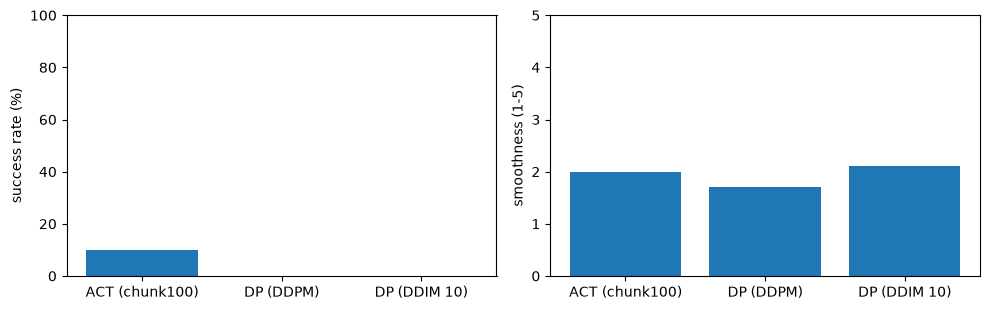

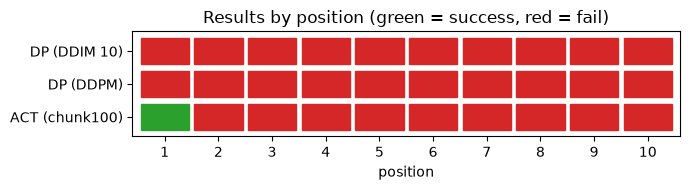

In [32]:
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
labels = list(summary.index)
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_ylabel("success rate (%)")
axes[1].bar(labels, summary["mean_smooth"]); axes[1].set_ylim(0, 5)
axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = 조건, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CONDITIONS):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CONDITIONS) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CONDITIONS)))
ax.set_yticklabels([LABELS[k] for k in CONDITIONS]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
과제 3의 3-4와 같은 방법으로, DP (DDPM)과 DP (DDIM 10)을 각각 3회씩 추가로 시도한다. 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮기고**, 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음) ACT는 과제 3의 반응성 테스트 결과와 비교한다.

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다. DDIM 10은 `--policy.noise_scheduler_type=DDIM --policy.num_inference_steps=10`을 함께 준다.

`[작성]` 아래 `reactivity`를 채운다.

In [31]:
import pandas as pd

reactivity = {
    "dp": [
        {
            "trial": 0,
            "followed": False,
            "note": "큐브를 옮긴 뒤에도 새 위치를 따라가지 못하고 로봇 팔이 위쪽을 향함.",
        },
        {
            "trial": 1,
            "followed": False,
            "note": "옮겨진 큐브의 새 위치를 찾지 못하고 기존 위치 근처에서 계속 헤맴.",
        },
        {
            "trial": 2,
            "followed": False,
            "note": "큐브를 오른쪽으로 옮겼지만 이동을 수정하지 못하고 지나치게 왼쪽으로 향함.",
        },
    ],

    "dp_ddim10": [
        {
            "trial": 0,
            "followed": False,
            "note": "큐브의 위치를 바꾼 뒤에도 새 위치에 반응하지 않고 팔이 위쪽을 향함.",
        },
        {
            "trial": 1,
            "followed": False,
            "note": "옮겨진 큐브 근처에서 방향을 제대로 결정하지 못하고 반복적으로 헤맴.",
        },
        {
            "trial": 2,
            "followed": False,
            "note": "큐브의 새 위치와 반대되는 왼쪽 방향으로 크게 이동하여 따라가지 못함.",
        },
    ],
}

react_df = pd.concat(
    [
        pd.DataFrame(rows).assign(condition=LABELS[condition])
        for condition, rows in reactivity.items()
    ],
    ignore_index=True,
)

print(
    react_df.groupby("condition", sort=False)["followed"]
    .apply(lambda values: f"{int(values.sum())}/3")
)

react_df

condition
DP (DDPM)       0/3
DP (DDIM 10)    0/3
Name: followed, dtype: object


,trial,followed,note,condition
0,0,False,큐브를 옮긴 뒤에도 새 위치를 따라가지 못하고 로봇 팔이 위쪽을 향함.,DP (DDPM)
1,1,False,옮겨진 큐브의 새 위치를 찾지 못하고 기존 위치 근처에서 계속 헤맴.,DP (DDPM)
2,2,False,큐브를 오른쪽으로 옮겼지만 이동을 수정하지 못하고 지나치게 왼쪽으로 향함.,DP (DDPM)
3,0,False,큐브의 위치를 바꾼 뒤에도 새 위치에 반응하지 않고 팔이 위쪽을 향함.,DP (DDIM 10)
4,1,False,옮겨진 큐브 근처에서 방향을 제대로 결정하지 못하고 반복적으로 헤맴.,DP (DDIM 10)
5,2,False,큐브의 새 위치와 반대되는 왼쪽 방향으로 크게 이동하여 따라가지 못함.,DP (DDIM 10)


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
ACT와 Diffusion Policy의 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: ACT의 청크 경계 튐, DP의 추론 중 멈칫함, DDIM 10의 궤적 흔들림)

![ACT 평가 영상](https://raw.githubusercontent.com/yhkees/git_test_repo/main/hw4_act.gif)

![DP DDPM 평가 영상](https://raw.githubusercontent.com/yhkees/git_test_repo/main/hw4_dp.gif)

![DP DDIM 10 평가 영상](https://raw.githubusercontent.com/yhkees/git_test_repo/main/hw4_dp_ddim10.gif)

## 4. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다. 가능하면 3절의 수치나 영상 장면을 근거로 든다.

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.

실험 결과 ACT의 성공률이 10%로 가장 높았고, DP (DDPM)과 DP (DDIM 10)는 모두 0%였다. 따라서 DP (DDPM)의 성공률이 가장 높을 것이라는 가설은 맞지 않았다. Diffusion Policy는 여러 행동 경로를 표현할 수 있지만, 이번 학습 데이터 50개만으로는 검은 큐브의 위치에 따라 안정적인 접근과 파지를 생성하기 어려웠던 것으로 보인다. 특히 큐브 근처에 도달하지 못하거나 팔이 위쪽을 향하는 동작이 반복된 것으로 보아, 실제 평가 환경에서 정책이 학습 데이터의 행동 분포를 벗어난 출력을 생성한 것으로 판단된다.

**4-2. 행동 생성 방식의 차이** — ACT와 Diffusion Policy의 동작에서 관찰된 차이(궤적의 부드러움, 머뭇거림, 파지 위치 선택 등)를 두 정책의 행동 생성 방식(회귀와 샘플링)으로 설명하라.

평균 부드러움은 ACT가 2.0점, DP (DDPM)가 1.7점, DP (DDIM 10)가 2.1점으로 측정되었다. ACT는 관측에 대응하는 행동 시퀀스를 회귀 방식으로 직접 예측하기 때문에 출력 경로가 비교적 일정했지만, 큐브 위치와 어긋난 경우에는 잘못된 경로를 계속 실행했다. Diffusion Policy는 노이즈에서 행동 시퀀스를 샘플링하므로 다양한 행동을 생성할 수 있지만, 이번 실험에서는 큐브 근처에서 헤매거나 팔이 위쪽을 향하는 불안정한 결과가 나타났다. 따라서 행동을 샘플링할 수 있다는 장점이 실제 성공으로 이어지려면 더 다양하고 충분한 학습 데이터가 필요하다고 판단된다.

**4-3. denoising 횟수와 실시간성** — DDIM 10에서 성공률, 부드러움, 추론 때문에 멈칫하는 정도가 DDPM과 비교해 어떻게 달라졌는가? 실시간 제어 관점에서 적절한 denoising 횟수는 얼마라고 보는가?

DDIM 10은 DDPM보다 denoising 횟수가 적어 평균 부드러움이 1.7점에서 2.1점으로 높아졌지만, 두 조건의 성공률은 모두 0%였다. 추론 계산량이 줄어들면서 일부 회차의 움직임은 상대적으로 덜 끊겼지만, 큐브의 위치를 정확히 찾고 파지하는 능력은 개선되지 않았다. 이는 10회의 denoising만으로는 행동의 정확도를 확보하기에 부족했을 가능성을 보여준다. 실시간성과 행동 정확도를 함께 고려하면 10과 100 사이인 20~50회의 denoising을 추가로 비교해 적절한 값을 찾는 것이 필요하다.

**4-4. 반응성** — Diffusion Policy는 `n_action_steps`마다 다시 추론한다. 반응성 테스트 결과를 과제 3의 ACT 결과와 비교하고, 차이를 다시 추론하는 주기로 설명하라.

반응성 테스트에서 DP (DDPM)과 DP (DDIM 10)는 모두 3회 중 0회만 이동한 큐브를 따라갔다. 과제 3에서 사용한 ACT chunk100도 긴 행동 청크를 실행하기 때문에 이동한 큐브에 빠르게 대응하기 어려운 조건이었다. Diffusion Policy는 `n_action_steps=32`이므로 평가 속도 25 fps를 기준으로 약 1.28초마다 다시 추론하지만, 실제로는 새 위치를 따라가지 못하고 기존 위치 주변에서 헤매거나 반대 방향으로 이동했다. 따라서 다시 추론하는 주기가 ACT보다 짧더라도, 정책이 새 관측에서 큐브 위치를 정확히 인식하지 못하면 반응성이 개선되지 않는다는 것을 확인했다.

**4-5. 내 태스크에 맞는 정책** — 학습 시간, 추론 속도, 성공률을 함께 고려할 때 본인 태스크에는 ACT와 Diffusion Policy 중 무엇이 적합한가? 그 정책을 더 개선하려면 무엇을 바꿔 보겠는가?

이번 검은 큐브 파지 태스크에는 ACT가 더 적합하다고 판단한다. Diffusion Policy의 학습 시간은 약 1시간 33분으로 짧았지만 성공률이 0%였고, ACT는 낮은 수치이지만 10%의 성공률을 기록했다. 현재 단계에서는 학습 시간보다 실제 로봇에서 한 번이라도 안정적으로 큐브를 잡을 수 있는지가 더 중요하다. ACT를 개선하려면 실패가 많았던 큐브 위치의 시연 데이터를 추가하고, 다양한 접근 방향을 균형 있게 수집하며, 더 짧은 행동 청크나 temporal ensemble을 적용해 위치 오차를 자주 수정하도록 할 수 있다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [34]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in EVAL_DATASETS.values()),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "Diffusion Policy 업로드됨 (config.json, model.safetensors)": (
        file_ok(DP_POLICY_REPO, "config.json", "model") and file_ok(DP_POLICY_REPO, "model.safetensors", "model")),
    "ACT와 같은 학습 데이터셋 사용 (1-3)": bool(same_dataset),
}
for k in CONDITIONS:
    check_items[f"{LABELS[k]} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"{LABELS[k]} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"{LABELS[k]} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["반응성 테스트 6회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] 학습 데이터셋 접근 가능 (public)
[통과] Diffusion Policy 업로드됨 (config.json, model.safetensors)
[통과] ACT와 같은 학습 데이터셋 사용 (1-3)
[통과] ACT (chunk100) 평가 데이터셋 에피소드 10개
[통과] ACT (chunk100) 회차별 결과 10개 입력
[통과] ACT (chunk100) 실패 회차에 원인 기재
[통과] DP (DDPM) 평가 데이터셋 에피소드 10개
[통과] DP (DDPM) 회차별 결과 10개 입력
[통과] DP (DDPM) 실패 회차에 원인 기재
[통과] DP (DDIM 10) 평가 데이터셋 에피소드 10개
[통과] DP (DDIM 10) 회차별 결과 10개 입력
[통과] DP (DDIM 10) 실패 회차에 원인 기재
[통과] 반응성 테스트 6회 입력

모두 통과
